# Assignment 2: Critical Application and Evaluation of Simple Linear Regression
#### Student Name: Gabriel Kariuki
#### Course code: STA6110Z -Linear and non Linear Models
#### Institution: USIU - Africa
#### Due date: Friday 18/09/2026 11:59PM

## Declaration of required Libraries
### First step is to declare and import all required libraries for data manipulation, statistical modelling, visual diagnostics and numeralical evaluation.

## Reproducibility & Execution Instructions

To ensure seamless execution and complete reproducibility, this document is configured to run end-to-end without local file path dependencies. 

### 1. Prerequisites & Required Libraries
Ensure you are using **Python 3.8+**. The analysis relies on standard statistical and data science packages listed below:
* `pandas` (>= 1.3.0) — Data manipulation and table generation
* `numpy` (>= 1.20.0) — Numerical computations
* `matplotlib` (>= 3.4.0) — Visualizations
* `seaborn` (>= 0.11.0) — Regression plots and diagnostic aesthetics
* `statsmodels` (>= 0.12.0) — OLS regression modeling and diagnostics
* `scipy` (>= 1.7.0) — Q-Q probability plots and statistical distributions

### 2. Environment Setup (Optional)
If running in a fresh Python environment, install all required dependencies by executing the following command in your terminal or a notebook cell:

```bash
pip install pandas numpy matplotlib seaborn statsmodels scipy

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
import scipy.stats as stats

#set global plot style
sns.set(style="whitegrid")
plt.rcParams["font.family"] = 'Sans-serif'
plt.rcParams["figure.dpi"] = 300
print('Environment initialized')


Environment initialized


## Question 1: Dataset Selection and Analytical Formulation

### a. Dataset and source citation
The dataset chosen for this critical analysis is the Auto MPG Dataset compiled by Ross Quinlan 1993 and sourced by the Carnegie Mellon University Statistics Library via the UCI Machine Learning Repository

#### Dataset Link: https://github.com/mwaskom/seaborn-data/blob/master/mpg.csv
#### Population: Passenger automobiles/vehicles produced between 1970's and early 1980's.
#### Observational Unit: Individual Automobiles models (e.g. 1970 Chevrolet Chevelle Malibu)
#### Geographical scope: Vehicles Manufactured in the USA, Europe and Japan
#### Period covered: 1970-1982 model years

### b. Variable definitions and Measurement units 
#### Dependent Variable (y): 'mpg' - Fuel efficiency measured in MilesPerGallon(MPG). Higher values indicate a greater/better fuel economy.
#### Independent Variable (x): 'weight' - Total curb weight of the vehicle measured in Pounds (lbs)

### c. Research Question
#### "To what extent does vehicle curb weight (x, in lbs) linearly predict automotive fuel efficiency (y, in mpg) among passenger vehicles manufactured between 1970-1982?"

### Statistical Hypothesis
#### Let $\beta_1$ represent the population slope parameter for the simple linear regression model $Y = \beta_0 + \beta_1 X + \varepsilon$:
#### Null Hypothesis ($H_0$): $\beta_1 = 0$
(There are no linear relationship between vehicle curb weight and fuel efficiency; changes in weight do not linearly alter the MPG).
#### Alt Hypothesis ($H_1$): $\beta_1 \neq 0$
(There is a statisically significant linear relationship between vehicle curb weight and fuel efficiency).

### d. Summary Statistics & Critical Data Evaluation

In [2]:
# Load the dataset from the raw CSV file
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/mpg.csv"
df_raw = pd.read_csv(url)

# Clean the dataset
df = df_raw[['mpg', 'weight']].dropna().copy()

# Compute summary statistics
summary_stats = pd.DataFrame({
    'Metric': ['Sample Size (N)', 'Mean', 'Median', 'Standard Deviation', 'Variance', 'Minimum', 'Maximum'],
    'Vehicle Weight (X, lbs)': [
        len(df['weight']),
        df['weight'].mean(),
        df['weight'].median(),
        df['weight'].std(),
        df['weight'].var(),
        df['weight'].min(),
        df['weight'].max()
    ],
    'Fuel Efficiency (Y, MPG)': [
        len(df['mpg']),
        df['mpg'].mean(),
        df['mpg'].median(),
        df['mpg'].std(),
        df['mpg'].var(),
        df['mpg'].min(),
        df['mpg'].max()
    ]
})

print("Table 1: Summary Statistics for Vehicle Weight and Fuel Efficiency")
summary_stats

Table 1: Summary Statistics for Vehicle Weight and Fuel Efficiency


,Metric,"Vehicle Weight (X, lbs)","Fuel Efficiency (Y, MPG)"
0,Sample Size (N),398.000000,398.000000
1,Mean,2970.424623,23.514573
2,Median,2803.500000,23.000000
3,Standard Deviation,846.841774,7.815984
4,Variance,717140.990526,61.089611
5,Minimum,1613.000000,9.000000
6,Maximum,5140.000000,46.600000


### Critical Commentary on Data Suitability
#### 1. Sample Size: The dataset contains $N = 398$ complete observations, well above the minimum threshold of 30, providing sufficient statistical power to estimate regression parameters precisely.
#### 2. Measurement scale: Both variables are continuous ratio-scale numerical measurements, satisfying structural input requirements for ordinary least squares regression.
#### 3. Distribution Dynamics: The mean weight $2970.4246$ lbs closely aligns with the median $2803.5$ lbs though the max weight is $5140.0$ lbs shows mid-right skewness. Mean MPG $23.51$ and median $23.00$ show notable symmetry, making the data generally suitable for preliminary linear modeling.

---
## Question 2 Model Implementation and Statistical Evidence

### a. Regression Scatter plot with fitted line

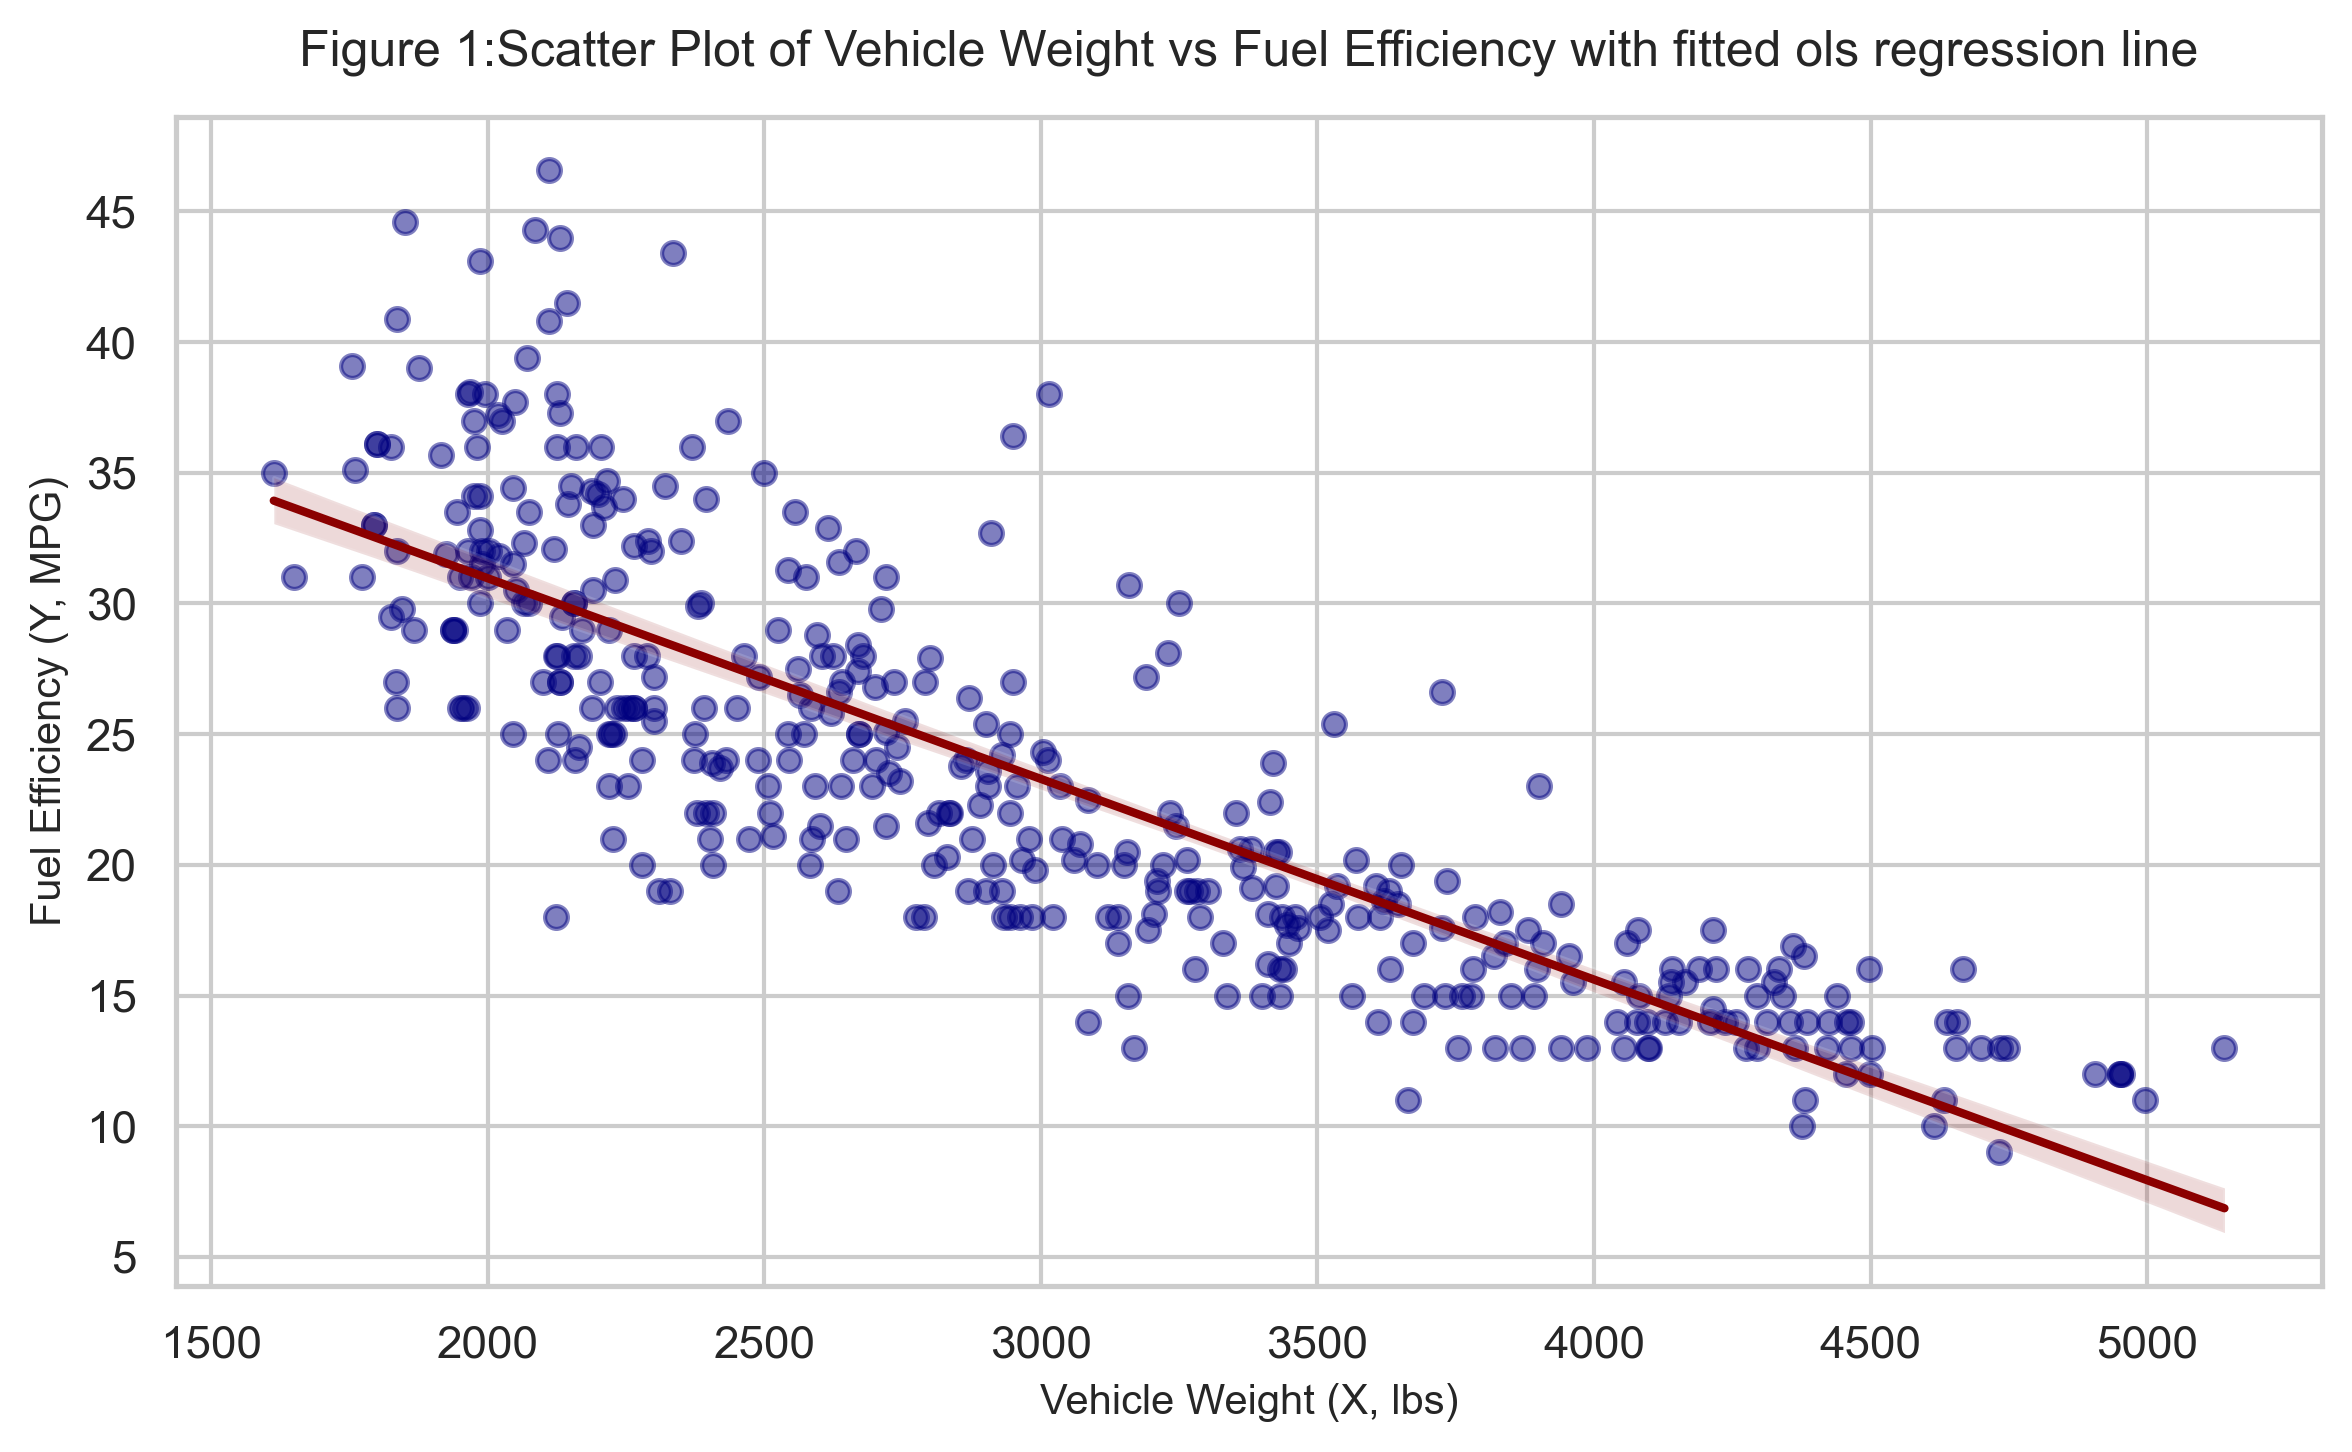

In [3]:
# Figure 1: Scatter plot of Vehicle Weight vs Fuel Efficiency with fitted ols regression line
plt.figure(figsize=(8, 5))
sns.regplot(
    data= df, x='weight', y='mpg',
    color='navy',
    line_kws={'color': 'darkred', 'linewidth': 2},
    scatter_kws={'alpha': 0.5, 's': 30}
    )
plt.title('Figure 1:Scatter Plot of Vehicle Weight vs Fuel Efficiency with fitted ols regression line', fontsize= 12, pad = 12)
plt.xlabel('Vehicle Weight (X, lbs)', fontsize= 10)
plt.ylabel('Fuel Efficiency (Y, MPG)', fontsize= 10)
plt.tight_layout()
plt.show()

 Figure 1 shows a strong, negative association between vehicle curb weight and fuel effciency. As vehicle mass increases the fuel efficiency decreases consistently. However, close visual inspection reveals a pronouced curvature: fuel efficiency declines steeply at lower weight thresholds(1500-2500lbs) and flattens out at a higher weight thresholds (above3000 lbs). This suggests that a strictly linear model will misestimate predictions at extreme values

### b. Model Estimate Output

In [4]:
# Fit the OLS regression model
model = smf.ols('mpg ~ weight', data=df).fit()

#Display model coefficients table
print("Table 2: OLS Regression Parameter Estimates")
print(model.summary().tables[1])

print("\nOverall Fit Metrics")
print(f"R-squared: {model.rsquared:.4f}")
print(f"Adjusted R-squared: {model.rsquared_adj:.4f}")
print(f"F-statistic: {model.fvalue:.2f} (P-VALUE: {model.f_pvalue:.4e})")

Table 2: OLS Regression Parameter Estimates
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     46.3174      0.795     58.243      0.000      44.754      47.881
weight        -0.0077      0.000    -29.814      0.000      -0.008      -0.007

Overall Fit Metrics
R-squared: 0.6918
Adjusted R-squared: 0.6910
F-statistic: 888.85 (P-VALUE: 2.9728e-103)


#### Estimated Regression Equation
$$\widehat{\text{MPG}} =46.3174 - 0.007677 \times \text{Weight}$$
### c Evaluation of Statistical Evidence & Practical Importance 

1. Statistical Significance:
    - Slope parameter ($\hat{\beta}_1$):** $-0.007677$ ($SE = 0.000257$).
    - Test statistic $t = -29.814$, $p < 0.0001$.
    - F-test: $F(1, 396) = 888.85, $p < 0.0001$.
    - Decision: Reject $H_0$ at $\alpha = 0.05$.. There is a strong statistical evidence of a linear association between vehicle weight and fuel efficiency. 
2. Practical importance vs Statistical significance:
    - Although the slope coefficient ($-0.007677$) appears small numerically because the unit of measurement is a single pound, its practical engineering impact is high. Scaling to industry-standard increments:
        $$\Delta Y_{\text{per 1,000lbs}} = -0.007677 \times 1,000 = -7.68 \text{ MPG}$$
    - Reducing vehicle mass by 1,000 lbs yields an expected fuel economy gain of nearly 7.7 miles per gallon, demonstrating high practical significance.
### d. Residual Diagnostics

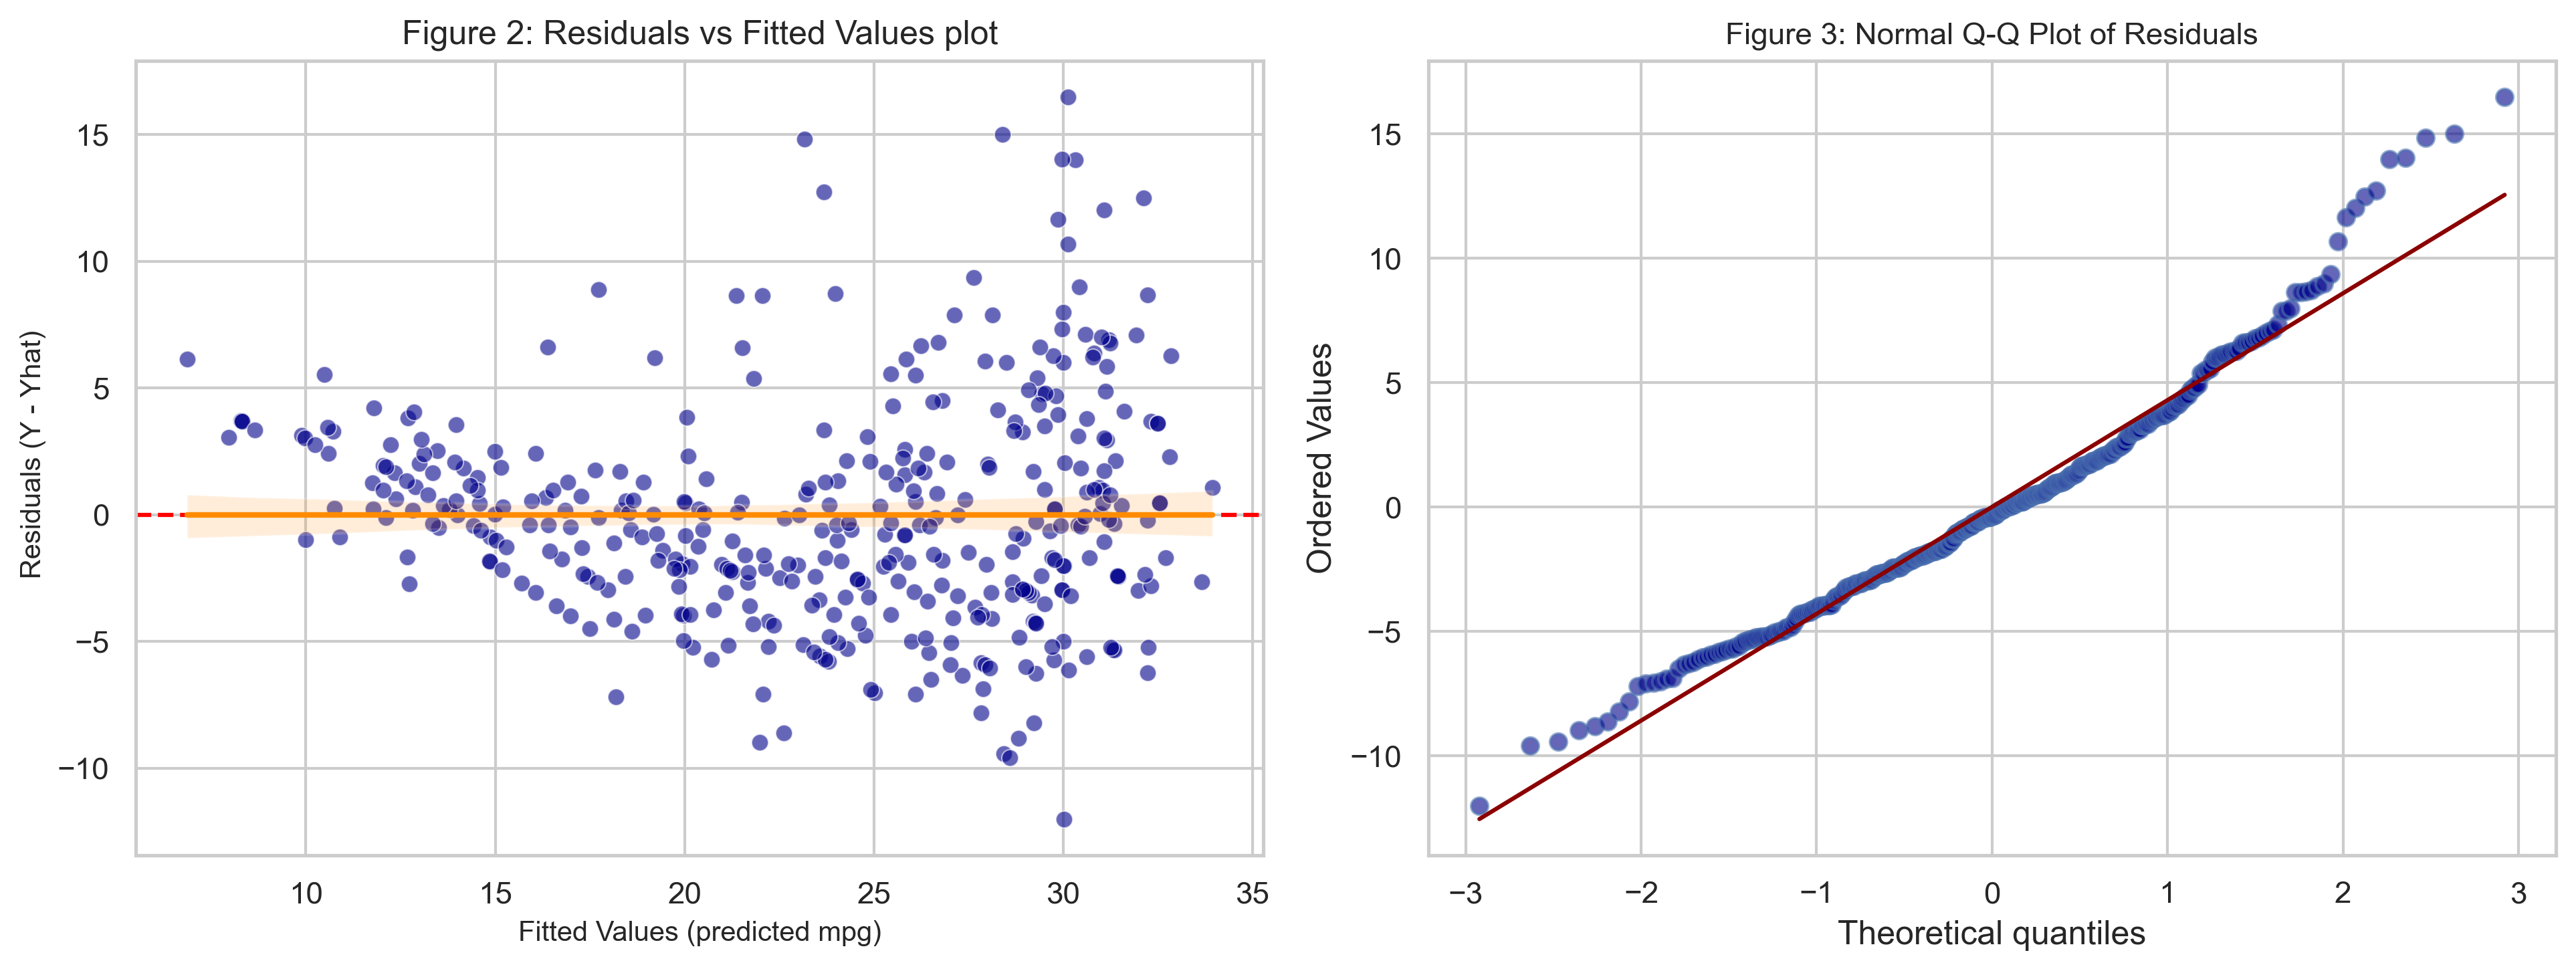

In [5]:
# Extract fitted values and raw residuals
fitted_vals = model.fittedvalues
residuals = model.resid

#Generate diagnostic plots
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

#Figure 2: Residuals vs Fitted Values
sns.scatterplot(x=fitted_vals, y=residuals, ax=axes[0], alpha=0.6, color='darkblue')
axes[0].axhline(0, color='red', linestyle='--', linewidth=1.5)
sns.regplot(x=fitted_vals, y=residuals, ax=axes[0], scatter=False, color='darkorange', line_kws={'linewidth': 2})
axes[0].set_title('Figure 2: Residuals vs Fitted Values plot', fontsize=12)
axes[0].set_xlabel('Fitted Values (predicted mpg)', fontsize=10)
axes[0].set_ylabel(" Residuals (Y - Yhat)", fontsize=10)

# Figure 3: Normal Q-Q Plot
stats.probplot(residuals, dist="norm", plot=axes[1])
axes[1].get_lines()[0].set_markerfacecolor('darkblue')
axes[1].get_lines()[0].set_alpha(0.6)
axes[1].get_lines()[1].set_color('darkred')
axes[1].set_title('Figure 3: Normal Q-Q Plot of Residuals', fontsize=11)

plt.tight_layout()
plt.show()

#### Diagnostic Assessment
    - Figure 2 shows a systematic U-shaped structural curve (highlighted by the lowess trend curve). Residuals are positive at extreme predicted values and negative in the mid-range. This pattern confirms a violation of the linearity assumption
    - Figure 3 shows right-tail departure from the theoretical normal line, indicating positive skewness in the residual errors. 

### Question 3 Interpretation and Critical Evaluation

#### a. Interpretation of the intercept ($\hat{\beta}_0$)
    - Value: $\hat{\beta}_0 = 46.3174$ MPG.
    - Meaning: A theoretical automobile weighing $0$ pounds is predicted to achieve a fuel efficiency of $46.32$ MPG.
    - Evaluation: The intercept lacks practical real world meaning. A vehicle weighing zero pounds cannot exist, and $X = 0$ lies well outside the observed the empirical domain ($1,6134 to $5,140$ lbs), making the term purely an anchoring constant for the linear equation. 

#### b. Interpretation of the slope ($\hat{\beta}_1$)
    - Value: $\hat{\beta}_1 = -0.007677$ per pound. 
    - Meaning: Holding all other factors constant, each 1 pound increase in vehicle weight reduces predicted fuel efficiency by $0.007677$ MPG (or $-7.68$ per $1,000$ lbs added).

#### c. Interpretation of $R^2$ (Coefficient of Determination)
    - Value: $R^2 = 0.6918$ ($69.18\%$).
    - Explanatory Performance: $69.18\%$ of the total variation in vehicle fuel efficiency is explained by linearity by vehicle weight. The remaining $30.82$ of variance is driven by unmodeled variables (e.g., engine displacement, aerodynamics) and non linear relationships.

#### d. Point Prediction within observed range
- Selected input value: $X_0 = 3,000 lbs.
-Substitution into regression equation:
    $$\widehat{\text{MPG}} = 46.3174 - 0.007677 \times (3,000)$$
    $$\widehat{\text{MPG}} = 46.3174 - 23.031 = 23.2864 \text{ MPG}$$

In [6]:
# Code verification
pred_val = model.predict(pd.DataFrame({'weight': [3000]}))[0]
print (f"Programmatic Prediction for X = 3000 lbs: {pred_val:.4f} MPG")

Programmatic Prediction for X = 3000 lbs: 23.2875 MPG


#### e. Conclusion
Adequate baseline explanation, but inadequate for relaible prediction.
#### Integrated justification
1. Statistical output: High $R^2$ ($0.6926$) and strong statistical significance ($p < 0.0001$) indicate a clear linear association
2. Diagnostic evidence: Diagnostic plots show clear non-linear patterns(U-shaped residuals), proving that a straight line model systematically misfits the data structure
3. Conclusion: A simple linear regression model is insufficient. A quadratic regression model ($Y = \beta_0 + \beta_1 X + \beta_2 X^2$) or a logarithmic transformation ($\ln(Y)$) is required to capture the true curved relationship.

#### Limitations
1. Model Specific Limitations (Non- Linear Physics): Automotive energy loss experiences diminishing returns as mass increases. A simple linear equation fails to model this non linear physical process
2. Data & Scope Limitation (Omitted variable Bias & Historical Epoch): Key variables such as aerodynamic drag, engine displacement and gear ratios omitted. Additionally, because the data spans 1970-1982 vehicles, the results cannot be directly generalized to modern automotive technologies.

---
### References

1. De Veaux, R. D., Velleman, P. F., & Bock, D. E. (2019). *Stats: Data and Models* (5th ed.). Pearson.
2. Quinlan, R. (1993). *Auto MPG Data Set*. UCI Machine Learning Repository. Carnegie Mellon University.
3. Wooldridge, J. M. (2020). *Introductory Econometrics: A Modern Approach* (7th ed.). Cengage Learning.